# EDA

The EDA phase will consist of reading the raw dataset files that are sourced from [HEESI 2024](https://www.esdm.go.id/en/publication/handbook-of-energy-economic-statistics-of-indonesia-heesi) which is an annual publication from Kementerian ESDM. Relevant to this notebook, we sourced information regarding statistics that are recorded by the Ministry, particularly those related to both green and fossil fuel energy.

The bulk of the effort within this notebook is data wrangling, that is:
* Importing the data
* Manipulation of data structure
* Correction or coercion of data types
* Cleaning missing values where necessary
* Export the dataset into a usable format (CSV) for the next phases

# 3.1

### Data Wrangling for Table 3.1
For this dataset, we performed several key cleaning steps:
* **Handling Missing Values:** Nulls for renewable variables (Wind, Solar, etc.) prior to 2018 were filled with `0` based on historical context, while other specific variables with inconsistent recording were left as is.
* **Type Casting:** Ensured the 'Year' column is correctly stored as an integer.
* **Exporting:** Saved the finalized version as `data_bersih_df_31.csv`.

In [98]:
import pandas as pd

df_31 = pd.read_csv(
    "raw_dataset/final dataset_datamining 3.1.csv",
    sep=';',
    thousands=',',
    na_values='n.a'
)

df_31.head()

,Year,Coal,Crude Oil & Product,Natural Gas & Product,Hydro Power,Geothermal,Solar PP & Solar PV,Wind,Other renew-ables,Solar Powered Public Street Lighting & Energy Saving Lamp,Traditional Biomass,Biofuel,BioGas,Industrial Biomass,Solar Water Heater,Direct Use of Geo-thermal,Total
0,2014,319956003,577688014,269636449,37955765,16191566,NaN,NaN,NaN,NaN,47686087,11966513,NaN,NaN,NaN,NaN,1281080397
1,2015,364619216,509485005,277793372,34604474,16337878,NaN,NaN,NaN,NaN,40096791,8380587,120162.0,1202.0,NaN,NaN,1251557683
2,2016,380310000,532134133,286140751,47450306,17537710,NaN,NaN,NaN,NaN,36085192,20625241,144549.0,185041.0,NaN,NaN,1320612924
3,2017,407526000,553121237,278963982,47599892,20259621,NaN,NaN,NaN,NaN,29332604,20947287,15714.0,18581.0,NaN,NaN,1358093574
4,2018,483335998,567189661,285286127,40204916,26040932,355896.0,466082.0,30493437.0,8795.0,27997958,28312237,162745.0,341891.0,NaN,NaN,1490196675


In [99]:
df_31.info()

<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 17 columns):
 #   Column                                                     Non-Null Count  Dtype  
---  ------                                                     --------------  -----  
 0   Year                                                       11 non-null     int64  
 1   Coal                                                       11 non-null     int64  
 2   Crude Oil & Product                                        11 non-null     int64  
 3   Natural Gas & Product                                      11 non-null     int64  
 4   Hydro Power                                                11 non-null     int64  
 5   Geothermal                                                 11 non-null     int64  
 6   Solar PP & Solar PV                                        7 non-null      float64
 7   Wind                                                       7 non-null      float64
 8   Other renew-ables      

In [100]:
for col in df_31.columns:
    print(f"Unique values in '{col}': {df_31[col].unique()}")

Unique values in 'Year': [2014 2015 2016 2017 2018 2019 2020 2021 2022 2023 2024]
Unique values in 'Coal': [319956003 364619216 380310000 407526000 483335998 581356407 553923901
 558782122 745721066 735542521 803864256]
Unique values in 'Crude Oil & Product': [577688014 509485005 532134133 553121237 567189661 545007702 471002427
 493428112 554614889 554391240 573857851]
Unique values in 'Natural Gas & Product': [269636449 277793372 286140751 278963982 285286127 284645039 299926865
 302911101 308152429 317046736 321925780]
Unique values in 'Hydro Power': [37955765 34604474 47450306 47599892 40204916 39329376 45206315 45947523
 50781201 45676673 50826030]
Unique values in 'Geothermal': [16191566 16337878 17537710 20259621 26040932 26193174 28909243 29532560
 30978688 31459399 31138930]
Unique values in 'Solar PP & Solar PV': [     nan  355896.  461856.   70414.  788979. 1705507. 3032918. 5989211.]
Unique values in 'Wind': [     nan  466082. 1185873. 1164203. 1070935.  872631. 1179535. 11

In [101]:
df_31.isnull().sum()

Year                                                         0
Coal                                                         0
Crude Oil & Product                                          0
Natural Gas & Product                                        0
Hydro Power                                                  0
Geothermal                                                   0
Solar PP & Solar PV                                          4
Wind                                                         4
Other renew-ables                                            4
Solar Powered Public Street Lighting & Energy Saving Lamp    4
Traditional Biomass                                          0
Biofuel                                                      0
BioGas                                                       1
Industrial Biomass                                           1
Solar Water Heater                                           8
Direct Use of Geo-thermal                              

In [102]:
col_miss = df_31[['Solar PP & Solar PV', 'Wind', 'Other renew-ables', 'Solar Powered Public Street Lighting & Energy Saving Lamp',
              'BioGas', 'Industrial Biomass', 'Solar Water Heater', 'Direct Use of Geo-thermal']]

In [103]:
for col in col_miss:
    df_31.loc[df_31['Year'] < 2018, col] = df_31.loc[df_31['Year'] < 2018, col].fillna(0)

Null variables dated in the range of years 2014-2017 are filled with a value of 0. This approach is based on the historical fact that PLTB (Pembangkit Listrik Tenaga Bayu) Sidrap, the first commercial level Wind-Powered generator, only first operated in March 2018 (Kementerian ESDM, 2018). Before that period, the contribution of wind-based energy to the national energy supply was not recorded as significant due to limited, experimental capacity that is limited to micro-grids.

[Source](https://www.esdm.go.id/id/berita-unit/direktorat-jenderal-ketenagalistrikan/presiden-resmikan-pembangkit-listrik-tenaga-angin-komersial-pertama-di-sidrap)

In [104]:
df_31.isnull().sum()

Year                                                         0
Coal                                                         0
Crude Oil & Product                                          0
Natural Gas & Product                                        0
Hydro Power                                                  0
Geothermal                                                   0
Solar PP & Solar PV                                          0
Wind                                                         0
Other renew-ables                                            0
Solar Powered Public Street Lighting & Energy Saving Lamp    0
Traditional Biomass                                          0
Biofuel                                                      0
BioGas                                                       0
Industrial Biomass                                           0
Solar Water Heater                                           4
Direct Use of Geo-thermal                              

In [105]:
df_31['Year'] = df_31['Year'].astype(int)

Null values in variables Solar Water Heater and Direct Use of Geothermal are not assumed to be 0. Instead, we recognise and identify this phenomenon due to limitations in consistency within the recording of sectoral data in Indonesia. Thus, analysis on those years may be slightly lower than reality (underestimation problem).

In [106]:
df_31.to_csv('data_bersih/data_bersih_df_31.csv', index=False)

# 6.4.1 (ongrid)

### Data Wrangling for Table 6.4.1 (On-Grid)
This process involved:
* **Standardization:** Renaming and cleaning column names to remove typos and technical suffixes (e.g., 'Geother-mal' to 'Geothermal').
* **Dimensionality Reduction:** Dropped the 'Other PP' column as it was identified as a Near-Zero Variance feature.
* **Exporting:** Saved the cleaned dataset to `data_bersih_df_641.csv`.

In [107]:
df_641 = pd.read_csv("raw_dataset/final dataset_datamining 6.4.1 (onGrid).csv",
                     sep=';',
                     thousands=',',
                     na_values='n.a')

In [108]:
df_641.columns = [
    col.replace(' 3)', '')
       .replace('Geother-mal', 'Geothermal')
       .replace('Coal Gasifi-cation', 'Coal Gasification')
       .strip()
    for col in df_641.columns
]

In [109]:
df_641.head()

,Year,Hydro PP,Steam PP,Gas PP,Combined Cycle PP,Geothermal PP,Diesel PP,Gas Engine PP,Wind PP,Micro Hydro PP,Mini Hydro PP,Solar PP,Coal Gasification PP,Waste PP,BioGas PP,Biomass PP,Other PP,Total On Grid
0,2014,5059.06,25104.23,4310.50,10146.11,1403.5,6206.99,610.74,1.12,30.46,139.87,9.02,6.0,36.00,0.00,0.00,NaN,53063.60
1,2015,5068.59,26447.58,4495.56,10293.47,1438.3,3824.07,1101.23,1.46,90.15,148.71,36.94,0.0,15.65,54.72,1671.29,NaN,54687.72
2,2016,5343.59,28351.97,4969.24,10293.47,1533.3,3979.40,1806.99,1.46,95.87,211.40,46.70,0.0,15.65,64.16,1703.29,NaN,58416.48
3,2017,5343.59,30768.07,4976.24,10418.47,1808.3,4396.35,2264.85,1.46,103.76,240.55,54.48,0.0,15.65,100.62,1740.54,NaN,62232.93
4,2018,4461.59,31587.17,5348.44,11220.10,1948.3,4630.90,2357.66,143.03,98.39,267.79,24.42,0.0,15.65,40.35,142.02,NaN,62285.81


In [110]:
df_641.isnull().sum()

Year                     0
Hydro PP                 0
Steam PP                 0
Gas PP                   0
Combined Cycle PP        0
Geothermal PP            0
Diesel PP                0
Gas Engine PP            0
Wind PP                  0
Micro Hydro PP           0
Mini Hydro PP            0
Solar PP                 0
Coal Gasification PP     0
Waste PP                 0
BioGas PP                0
Biomass PP               0
Other PP                10
Total On Grid            0
dtype: int64

In [111]:
df_641 = df_641.drop(columns=['Other PP'])

The `Other PP` column was identified as a Near-Zero Variance feature, due to having only one value in one year. Zero variance columns generally do not contribute new information to data mining algorithms, instead creating noise and increasing performance load for algorithms without yielding usable insights.

In [112]:
df_641.isnull().sum()

Year                    0
Hydro PP                0
Steam PP                0
Gas PP                  0
Combined Cycle PP       0
Geothermal PP           0
Diesel PP               0
Gas Engine PP           0
Wind PP                 0
Micro Hydro PP          0
Mini Hydro PP           0
Solar PP                0
Coal Gasification PP    0
Waste PP                0
BioGas PP               0
Biomass PP              0
Total On Grid           0
dtype: int64

In [113]:
df_641['Year'] = df_641['Year'].astype(int)

In [114]:
df_641.to_csv('data_bersih/data_bersih_df_641.csv', index=False)

# 6.4.1 (off grid)

### Data Wrangling for Table 6.4.1 (Off-Grid)
Steps taken for the off-grid dataset:
* **Column Cleaning:** Standardized column names and removed unnecessary features like 'Coal Gasification PP'.
* **Imputation:** Filled null values for variables with 0 to reflect the historical absence of commercial operations for those energy types in earlier years.
* **Exporting:** Saved as `data_bersih_df_641_off.csv`.

In [115]:
df_641_off = pd.read_csv(r"raw_dataset/final dataset_datamining 6.4.1 (offGrid).csv",
                         sep=';',
                         thousands=',',
                         na_values='n.a')

In [116]:
df_641_off.columns = [
    col.replace(' 4)', '')
       .replace('Coal Gasifi-cation', 'Coal Gasification')
       .replace('\n', ' ')
       .strip()
    for col in df_641_off.columns
]

In [117]:
df_641_off.head()

,Year,Hydro PP,Micro Hydro PP,Solar PP + PV,Wind PP,Biomass PP,Biogas PP,Coal Gasification PP,Hybrid PP,Solar-Powered Public Street Lighting,Solar-Powered Energy Saving Lamp,Total Off Grid,Grand Total On Grid + Off Grid
0,2014,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,53063.60
1,2015,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,54687.72
2,2016,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,58416.48
3,2017,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.00,62232.93
4,2018,938.0,6.38,28.19,0.48,1616.52,68.26,NaN,3.58,5.28,7.58,2668.99,64954.80


In [118]:
df_641_off.isnull().sum()

Year                                     0
Hydro PP                                 4
Micro Hydro PP                           4
Solar PP + PV                            4
Wind PP                                  4
Biomass PP                               4
Biogas PP                                4
Coal Gasification PP                    10
Hybrid PP                                4
Solar-Powered Public Street Lighting     4
Solar-Powered Energy Saving Lamp         4
Total Off Grid                           0
Grand Total On Grid + Off Grid           0
dtype: int64

In [119]:
df_641_off = df_641_off.drop(columns=['Coal Gasification PP'])
#drop kolom Coal Gasification PP karena

In [120]:
df_641_off = df_641_off.fillna(0)

Null variables in years 2014-2017 were filled with a value of 0. This represents the lack of a significant contribution from wind-powered geenration before PLTB Sidrap started operating at full scale in March 2018.

[Source](https://www.esdm.go.id/id/berita-unit/direktorat-jenderal-ketenagalistrikan/presiden-resmikan-pembangkit-listrik-tenaga-angin-komersial-pertama-di-sidrap)

In [121]:
df_641_off.isnull().sum()

Year                                    0
Hydro PP                                0
Micro Hydro PP                          0
Solar PP + PV                           0
Wind PP                                 0
Biomass PP                              0
Biogas PP                               0
Hybrid PP                               0
Solar-Powered Public Street Lighting    0
Solar-Powered Energy Saving Lamp        0
Total Off Grid                          0
Grand Total On Grid + Off Grid          0
dtype: int64

In [122]:
df_641_off['Year'] = df_641_off['Year'].astype(int)

In [123]:
df_641_off.to_csv('data_bersih/data_bersih_df_641_off.csv', index=False)

# 6.4.2_1

### Data Wrangling for Table 6.4.2_1 (Own & Purchased Power)
* **Structural Adjustment:** Sliced the dataframe to remove non-data header/footer rows and assigned descriptive column names for 'Own' vs 'Purchased' sources.
* **Custom Parsing:** Developed a conversion function to handle various string representations of nulls ('-', 'n.a') and formatted strings into numeric floats.
* **Exporting:** Saved as `data_bersih_clean_642_1.csv`.

In [124]:
df_642_1 = pd.read_csv("raw_dataset/final dataset_datamining 6.4.2_1.csv",
                       sep=';',
                       thousands=',',
                       na_values='n.a')

In [125]:
clean_642_1 = df_642_1.iloc[2:13].copy()

In [126]:
clean_642_1.columns = [
    'Year',
    'Own_Hydro_PP', 'Own_Geothermal_PP', 'Own_Solar_PP', 'Own_Diesel_PP',
    'Own_Steam_PP_Coal', 'Own_Steam_PP_Oil', 'Own_Steam_PP_Gas', 'Own_Steam_PP_Co_firing',
    'Own_Steam_PP_Total', 'Own_Combined_Gas_Steam_PP', 'Own_Gas_PP', 'Own_Gas_Engine_PP',
    'Own_Wind_PP', 'Own_Biomass_PP', 'Own_Sub_Total',
    'Purchase_Hydro_PP', 'Purchase_Geothermal_PP', 'Purchase_Solar_PP', 'Purchase_Diesel_PP',
    'Purchase_Steam_PP_Coal', 'Purchase_Steam_PP_Gas', 'Purchase_Steam_PP_Biomass',
    'Purchase_Steam_PP_Total'
]

In [127]:
clean_642_1.head()

,Year,Own_Hydro_PP,Own_Geothermal_PP,Own_Solar_PP,Own_Diesel_PP,Own_Steam_PP_Coal,Own_Steam_PP_Oil,Own_Steam_PP_Gas,Own_Steam_PP_Co_firing,Own_Steam_PP_Total,...,Own_Biomass_PP,Own_Sub_Total,Purchase_Hydro_PP,Purchase_Geothermal_PP,Purchase_Solar_PP,Purchase_Diesel_PP,Purchase_Steam_PP_Coal,Purchase_Steam_PP_Gas,Purchase_Steam_PP_Biomass,Purchase_Steam_PP_Total
2,2014.0,"11,164","4,285",6.81,"21,862","83,397",759,"5,856",-,"90,012",...,0,"175,297","3,998","5,753",0.00,418,"36,135",137,0,"36,477"
3,2015.0,"10,005","4,392",5.28,"18,859","85,191","11,419",146,-,"96,756",...,0,"176,472","3,736","5,656",0.00,633,"39,466",115,0,"40,043"
4,2016.0,"13,886","3,958",8.78,"19,122","92,682","1,092","4,488",-,"98,262",...,0,"183,809","4,791","6,698",12.31,586,"42,699",129,0,"43,411"
5,2017.0,"12,425","4,096",5.84,"16,453","101,333",285,"4,159",-,"105,778",...,0,"181,425","6,207","8,668",23.21,"2,110","46,631",263,0,"46,894"
6,2018.0,"10,729","4,013",4.56,"15,019","110,035",517,"3,846",4,"114,402",...,0,"188,698","6,099","10,006",14.71,"2,410","49,978",242,0,"50,220"


In [128]:
def clean_and_convert(val):
    if pd.isna(val):
        return 0.0
    val_str = str(val).strip().replace(',', '')
    if val_str in ['-', '', 'nan', 'n.a']:
        return 0.0
    try:
        return float(val_str)
    except ValueError:
        return val_str

Null variables in years 2014-2017 were filled with a value of 0. This represents the lack of a significant contribution from wind-powered geenration before PLTB Sidrap started operating at full scale in March 2018.

[Source](https://www.esdm.go.id/id/berita-unit/direktorat-jenderal-ketenagalistrikan/presiden-resmikan-pembangkit-listrik-tenaga-angin-komersial-pertama-di-sidrap)

In [129]:
for col in clean_642_1.columns:
    if col == 'Year':
        clean_642_1[col] = clean_642_1[col].astype(int)
    else:
        clean_642_1[col] = clean_642_1[col].apply(clean_and_convert)

In [130]:
clean_642_1.isnull().sum()

Year                         0
Own_Hydro_PP                 0
Own_Geothermal_PP            0
Own_Solar_PP                 0
Own_Diesel_PP                0
Own_Steam_PP_Coal            0
Own_Steam_PP_Oil             0
Own_Steam_PP_Gas             0
Own_Steam_PP_Co_firing       0
Own_Steam_PP_Total           0
Own_Combined_Gas_Steam_PP    0
Own_Gas_PP                   0
Own_Gas_Engine_PP            0
Own_Wind_PP                  0
Own_Biomass_PP               0
Own_Sub_Total                0
Purchase_Hydro_PP            0
Purchase_Geothermal_PP       0
Purchase_Solar_PP            0
Purchase_Diesel_PP           0
Purchase_Steam_PP_Coal       0
Purchase_Steam_PP_Gas        0
Purchase_Steam_PP_Biomass    0
Purchase_Steam_PP_Total      0
dtype: int64

In [131]:
clean_642_1.head()

,Year,Own_Hydro_PP,Own_Geothermal_PP,Own_Solar_PP,Own_Diesel_PP,Own_Steam_PP_Coal,Own_Steam_PP_Oil,Own_Steam_PP_Gas,Own_Steam_PP_Co_firing,Own_Steam_PP_Total,...,Own_Biomass_PP,Own_Sub_Total,Purchase_Hydro_PP,Purchase_Geothermal_PP,Purchase_Solar_PP,Purchase_Diesel_PP,Purchase_Steam_PP_Coal,Purchase_Steam_PP_Gas,Purchase_Steam_PP_Biomass,Purchase_Steam_PP_Total
2,2014,11164.0,4285.0,6.81,21862.0,83397.0,759.0,5856.0,0.0,90012.0,...,0.0,175297.0,3998.0,5753.0,0.00,418.0,36135.0,137.0,0.0,36477.0
3,2015,10005.0,4392.0,5.28,18859.0,85191.0,11419.0,146.0,0.0,96756.0,...,0.0,176472.0,3736.0,5656.0,0.00,633.0,39466.0,115.0,0.0,40043.0
4,2016,13886.0,3958.0,8.78,19122.0,92682.0,1092.0,4488.0,0.0,98262.0,...,0.0,183809.0,4791.0,6698.0,12.31,586.0,42699.0,129.0,0.0,43411.0
5,2017,12425.0,4096.0,5.84,16453.0,101333.0,285.0,4159.0,0.0,105778.0,...,0.0,181425.0,6207.0,8668.0,23.21,2110.0,46631.0,263.0,0.0,46894.0
6,2018,10729.0,4013.0,4.56,15019.0,110035.0,517.0,3846.0,4.0,114402.0,...,0.0,188698.0,6099.0,10006.0,14.71,2410.0,49978.0,242.0,0.0,50220.0


In [132]:
clean_642_1.to_csv('data_bersih/data_bersih_clean_642_1.csv', index=False)

# 6.4.2_2

### Data Wrangling for Table 6.4.2_2
* **Structure & Naming:** Applied row slicing to isolate relevant data and renamed columns for better clarity regarding off-grid and on-grid categories.
* **Data Coercion:** Applied uniform numeric conversion across all feature columns while converting the Year to an integer format.
* **Exporting:** Saved as `data_bersih_clean_642_2.csv`.

In [133]:
df_642_2 = pd.read_csv("raw_dataset/final dataset_datamining 6.4.2_2.csv",
                       sep=';',
                       thousands=',',
                       na_values='n.a')

In [134]:
clean_642_2 = df_642_2.iloc[2:13].copy()

In [135]:
clean_642_2.columns = [
    'Year',
    'Purchase_Combined_Gas_Steam_PP', 'Purchase_Gas_PP', 'Purchase_Gas_Engine_PP',
    'Purchase_Wind_PP', 'Purchase_Biomass_PP', 'Purchase_Biogas_PP', 'Purchase_Waste_PP',
    'Purchase_Sub_Total', 'Total_OnGrid',
    'OffGrid_Hydro_PP', 'OffGrid_Micro_Hydro_PP', 'OffGrid_Solar_PP_Solar_PV',
    'OffGrid_Wind_PP', 'OffGrid_Biomass_PP', 'OffGrid_Biogas_PP', 'OffGrid_Waste_PP',
    'OffGrid_Hybrid_PP', 'OffGrid_Solar_Powered_Public_Street_Lighting',
    'OffGrid_Solar_Powered_Energy_Saving_Lamp', 'Total_Off_Grid', 'Grand_Total'
]

In [136]:
clean_642_2.head()

,Year,Purchase_Combined_Gas_Steam_PP,Purchase_Gas_PP,Purchase_Gas_Engine_PP,Purchase_Wind_PP,Purchase_Biomass_PP,Purchase_Biogas_PP,Purchase_Waste_PP,Purchase_Sub_Total,Total_OnGrid,...,OffGrid_Solar_PP_Solar_PV,OffGrid_Wind_PP,OffGrid_Biomass_PP,OffGrid_Biogas_PP,OffGrid_Waste_PP,OffGrid_Hybrid_PP,OffGrid_Solar_Powered_Public_Street_Lighting,OffGrid_Solar_Powered_Energy_Saving_Lamp,Total_Off_Grid,Grand_Total
2,2014.0,4981,1595,0,0,205,0,36,53258,228555,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,228555
3,2015.0,5330,2090,0,4,461,0,19,57510,233982,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,233982
4,2016.0,5832,2767,0,6,584,0,6,64109,247918,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,247918
5,2017.0,5704,3002,35,0,534,52,5,73235,254660,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,254660
6,2018.0,4946,3841,41,188,526,95,1,78387,267085,...,56,2,"11,325",478,0,5,5,10,16690,283776


In [137]:
clean_642_2.isnull().sum()

Year                                            0
Purchase_Combined_Gas_Steam_PP                  0
Purchase_Gas_PP                                 0
Purchase_Gas_Engine_PP                          0
Purchase_Wind_PP                                0
Purchase_Biomass_PP                             0
Purchase_Biogas_PP                              0
Purchase_Waste_PP                               0
Purchase_Sub_Total                              0
Total_OnGrid                                    0
OffGrid_Hydro_PP                                4
OffGrid_Micro_Hydro_PP                          4
OffGrid_Solar_PP_Solar_PV                       4
OffGrid_Wind_PP                                 4
OffGrid_Biomass_PP                              4
OffGrid_Biogas_PP                               4
OffGrid_Waste_PP                                4
OffGrid_Hybrid_PP                               4
OffGrid_Solar_Powered_Public_Street_Lighting    4
OffGrid_Solar_Powered_Energy_Saving_Lamp        4


In [138]:
def clean_and_convert(val):
    if pd.isna(val):
        return 0.0
    val_str = str(val).strip().replace(',', '')
    if val_str in ['-', '', 'nan', 'n.a']:
        return 0.0
    try:
        return float(val_str)
    except ValueError:
        return val_str

In [139]:
for col in clean_642_2.columns:
    if col == 'Year':
        clean_642_2[col] = clean_642_2[col].astype(int)
    else:
        clean_642_2[col] = clean_642_2[col].apply(clean_and_convert)

Null variables in years 2014-2017 were filled with a value of 0. This represents the lack of a significant contribution from wind-powered geenration before PLTB Sidrap started operating at full scale in March 2018.

[Source](https://www.esdm.go.id/id/berita-unit/direktorat-jenderal-ketenagalistrikan/presiden-resmikan-pembangkit-listrik-tenaga-angin-komersial-pertama-di-sidrap)

In [140]:
clean_642_2.isnull().sum()

Year                                            0
Purchase_Combined_Gas_Steam_PP                  0
Purchase_Gas_PP                                 0
Purchase_Gas_Engine_PP                          0
Purchase_Wind_PP                                0
Purchase_Biomass_PP                             0
Purchase_Biogas_PP                              0
Purchase_Waste_PP                               0
Purchase_Sub_Total                              0
Total_OnGrid                                    0
OffGrid_Hydro_PP                                0
OffGrid_Micro_Hydro_PP                          0
OffGrid_Solar_PP_Solar_PV                       0
OffGrid_Wind_PP                                 0
OffGrid_Biomass_PP                              0
OffGrid_Biogas_PP                               0
OffGrid_Waste_PP                                0
OffGrid_Hybrid_PP                               0
OffGrid_Solar_Powered_Public_Street_Lighting    0
OffGrid_Solar_Powered_Energy_Saving_Lamp        0


In [141]:
clean_642_2.head()

,Year,Purchase_Combined_Gas_Steam_PP,Purchase_Gas_PP,Purchase_Gas_Engine_PP,Purchase_Wind_PP,Purchase_Biomass_PP,Purchase_Biogas_PP,Purchase_Waste_PP,Purchase_Sub_Total,Total_OnGrid,...,OffGrid_Solar_PP_Solar_PV,OffGrid_Wind_PP,OffGrid_Biomass_PP,OffGrid_Biogas_PP,OffGrid_Waste_PP,OffGrid_Hybrid_PP,OffGrid_Solar_Powered_Public_Street_Lighting,OffGrid_Solar_Powered_Energy_Saving_Lamp,Total_Off_Grid,Grand_Total
2,2014,4981.0,1595.0,0.0,0.0,205.0,0.0,36.0,53258.0,228555.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,228555.0
3,2015,5330.0,2090.0,0.0,4.0,461.0,0.0,19.0,57510.0,233982.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,233982.0
4,2016,5832.0,2767.0,0.0,6.0,584.0,0.0,6.0,64109.0,247918.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,247918.0
5,2017,5704.0,3002.0,35.0,0.0,534.0,52.0,5.0,73235.0,254660.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,254660.0
6,2018,4946.0,3841.0,41.0,188.0,526.0,95.0,1.0,78387.0,267085.0,...,56.0,2.0,11325.0,478.0,0.0,5.0,5.0,10.0,16690.0,283776.0


In [142]:
clean_642_2.to_csv('data_bersih/data_bersih_clean_642_2.csv', index=False)

# 7

### Data Wrangling for Table 7 (GHG Emissions)
* **Filtering:** Removed specific rows (e.g., '1.A.5. Other') that contained non-numeric notation ('NE,NO').
* **Transformation:** Transposed the dataset to convert categories into columns and years into rows for easier time-series integration.
* **Regex Cleaning:** Used regular expressions to strip numerical codes from category names for improved readability.
* **Exporting:** Saved as `data_bersih_df_7.csv`.

In [143]:
df_7 = pd.read_csv("raw_dataset/final dataset_datamining 7.csv",
                    sep=';',
                    thousands=',',
                    na_values='n.a')
df_7

,GREENHOUSE GAS SOURCE FROM ENERGY SECTORS,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,1. Energy,"539,153","549,956","535,998","582,068","614,425","655,568","605,367","623,127","738,753","745,011","790,566"
1,1.A. Fuel combustion,"510,923","521,803","509,029","553,962","586,182","628,039","579,834","598,322","715,445","724,236","770,641"
2,1.A.1. Energy industries,"226,005","237,474","256,338","268,562","286,868","297,581","306,256","330,586","315,594","292,515","321,886"
3,1.A.2. Manufacturing industries and construction,"87,734","98,885","76,712","82,078","106,519","138,295","105,616","89,988","206,524","231,618","244,334"
4,1.A.3. Transport,"144,946","130,391","127,765","152,363","156,981","159,367","134,838","143,415","158,339","165,178","168,516"
5,1.A.4. Other sectors,"52,239","55,053","48,215","50,959","35,814","32,797","33,124","34,333","34,987","34,924","35,904"
6,1.A.5. Other,"NE,NO","NE,NO","NE,NO","NE,NO","NE,NO","NE,NO","NE,NO","NE,NO","NE,NO","NE,NO","NE,NO"
7,1.B. Fugitive emissions from fuels,"28,230","28,152","26,969","28,106","28,243","27,529","25,533","24,805","23,309","20,775","19,925"
8,1.B.1. Solid fuels,"3,438","3,464","3,423","3,461","4,186","4,624","4,230","4,607","4,244","4,363","4,706"
9,1.B.2. Oil and natural gas and other emissions...,"24,792","24,689","23,546","24,645","24,057","22,905","21,303","20,198","19,065","16,413","15,219"


In [144]:
df_7.isnull().sum()

GREENHOUSE GAS SOURCE FROM ENERGY SECTORS    0
2014                                         0
2015                                         0
2016                                         0
2017                                         0
2018                                         0
2019                                         0
2020                                         0
2021                                         0
2022                                         0
2023                                         0
2024                                         0
dtype: int64

In [145]:
df_7 = df_7.rename(columns={df_7.columns[0]: 'Source'})

In [146]:
df_7 = df_7[df_7['Source'] != '1.A.5. Other'] # kita tidak menggunakan 1.A.5. Other valuenya hanya 'NE,NO'

In [147]:
df_7.set_index('Source', inplace=True)

In [148]:
def cleanCol_7(val):
  if pd.isna(val):
        return 0.0
  val_str = str(val).strip().replace(',', '')
  try:
      return float(val_str)
  except ValueError:
      return val_str

In [149]:
df_clean_7 = df_7.map(cleanCol_7)

In [150]:
df_transposed7 = df_clean_7.T
df_transposed7.index.name = 'Year'
df_transposed7 = df_transposed7.reset_index()

#karena kita perlu kolom year supaya disamakan dengan table lain sehingga saat di merge/join lebih mudah

In [151]:
df_transposed7['Year'] = df_transposed7['Year'].astype(int)

In [152]:
import re
def remove_leading_codes(col_name):
    if col_name == 'Year':
        return col_name
    return re.sub(r'^[0-9A-Z\.]+\s+', '', col_name) #membuang angka dan huruf yang ada di depan nama kolom

df_transposed7.columns = [remove_leading_codes(col) for col in df_transposed7.columns]

In [153]:
df_transposed7

,Year,Energy,Fuel combustion,Energy industries,Manufacturing industries and construction,Transport,Other sectors,Fugitive emissions from fuels,Solid fuels,Oil and natural gas and other emissions from energy production
0,2014,539153.0,510923.0,226005.0,87734.0,144946.0,52239.0,28230.0,3438.0,24792.0
1,2015,549956.0,521803.0,237474.0,98885.0,130391.0,55053.0,28152.0,3464.0,24689.0
2,2016,535998.0,509029.0,256338.0,76712.0,127765.0,48215.0,26969.0,3423.0,23546.0
3,2017,582068.0,553962.0,268562.0,82078.0,152363.0,50959.0,28106.0,3461.0,24645.0
4,2018,614425.0,586182.0,286868.0,106519.0,156981.0,35814.0,28243.0,4186.0,24057.0
5,2019,655568.0,628039.0,297581.0,138295.0,159367.0,32797.0,27529.0,4624.0,22905.0
6,2020,605367.0,579834.0,306256.0,105616.0,134838.0,33124.0,25533.0,4230.0,21303.0
7,2021,623127.0,598322.0,330586.0,89988.0,143415.0,34333.0,24805.0,4607.0,20198.0
8,2022,738753.0,715445.0,315594.0,206524.0,158339.0,34987.0,23309.0,4244.0,19065.0
9,2023,745011.0,724236.0,292515.0,231618.0,165178.0,34924.0,20775.0,4363.0,16413.0


In [154]:
df_transposed7.to_csv('data_bersih/data_bersih_df_7.csv', index=False)

# 6.1.2

### Data Wrangling for Table 6.1.2 (Coal)
* **Feature Engineering:** Calculated new metrics including 'Domestic Consumption' and 'Export Ratio'.
* **Parsing:** Used custom helpers to extract clean integer years and parse numeric strings containing commas/spaces.
* **Exporting:** Saved as `data_bersih_df_612.csv`.

In [155]:
def parse_num(s):
    try:
        return float(str(s).replace(',', '').replace(' ', ''))
    except:
        return np.nan

def clean_year(y):
    try:
        return int(str(y).split()[0])
    except:
        return np.nan

raw_coal = pd.read_csv("raw_dataset/final dataset_datamining(6.1.csv",
                        sep=';',
                        thousands=',',
                        na_values='n.a')

In [156]:
coal = raw_coal[raw_coal['Year'].notna()][['Year', 'Production 1)', 'Export', 'Import']].copy()
coal.columns = ['year', 'production', 'export', 'import']
coal['year']       = coal['year'].apply(clean_year)
coal['production'] = coal['production'].apply(parse_num)
coal['export']     = coal['export'].apply(parse_num)
coal['import']     = coal['import'].apply(parse_num)
coal = coal.dropna(subset=['year']).reset_index(drop=True)
coal['year']         = coal['year'].astype(int)
coal['domestic']     = coal['production'] - coal['export'] + coal['import']
coal['export_ratio'] = coal['export'] / coal['production'] * 100

In [157]:
print(f"Table 6.1 Coal: {coal.shape[0]} rows")
display(coal.head(3))
coal.to_csv('data_bersih/data_bersih_df_612.csv', index=False)

Table 6.1 Coal: 11 rows


,year,production,export,import,domestic,export_ratio
0,2014,458096707.0,381972830.0,2442319.0,78566196.0,83.382575
1,2015,461566080.0,365849610.0,3038701.0,98755171.0,79.262672
2,2016,456197775.0,331128438.0,4118833.0,129188170.0,72.584404


# 6.2.3

In [158]:
raw_oil = pd.read_csv("raw_dataset/final dataset_datamining(6.2.csv",
                    sep=';',
                    thousands=',',
                    na_values='n.a')

### Data Wrangling for Table 6.2.3 (Crude Oil)
* **Row Slicing:** Removed header noise to isolate time-series data.
* **Metric Extraction:** Parsed production and trade volumes and calculated 'Net Trade' (Export - Import).
* **Exporting:** Saved the finalized oil statistics as `data_bersih_df_623.csv`.

In [159]:
oil = raw_oil.iloc[2:][['Column1','Column2','Column3','Column4','Column5','Column6']].copy()
oil.columns = ['year','production','export','import','refinery_bbl','refinery_bpd']

for c in oil.columns:
    oil[c] = oil[c].apply(parse_num)
oil = oil.dropna(subset=['year']).reset_index(drop=True)
oil['year']      = oil['year'].astype(int)
oil['net_trade'] = oil['export'] - oil['import']

In [160]:
print(f"Table 6.1 Coal: {coal.shape[0]} rows")
display(coal.head(3))
coal.to_csv('data_bersih/data_bersih_df_623.csv', index=False)

Table 6.1 Coal: 11 rows


,year,production,export,import,domestic,export_ratio
0,2014,458096707.0,381972830.0,2442319.0,78566196.0,83.382575
1,2015,461566080.0,365849610.0,3038701.0,98755171.0,79.262672
2,2016,456197775.0,331128438.0,4118833.0,129188170.0,72.584404


# 6.4.5

### Data Wrangling for Table 6.4.5 (Power Plant Fuel)
* **Unit Conversion:** Converted various fuel units (Tons, KL, MMSCF) into a uniform energy metric: Million Tons of Oil Equivalent (MTOE) using standard conversion factors.
* **Market Share Analysis:** Calculated the percentage share of Coal and Renewable Energy relative to total consumption.
* **Exporting:** Saved as `data_bersih_df_645.csv`.

In [161]:
raw_pp = pd.read_csv("raw_dataset/final dataset_datamining(6.4.csv",
                    sep=';',
                    thousands=',',
                    na_values='n.a')

In [162]:
pp = raw_pp.iloc[1:].copy()
pp.columns = ['year','coal_ton','hsd_kl','ido_kl','fo_kl','gas_mmscf','biofame_kl','drop']
pp = pp.drop(columns=['drop'])
for c in pp.columns:
    pp[c] = pp[c].apply(parse_num)
pp = pp.dropna(subset=['year']).reset_index(drop=True)

In [163]:
pp['year']         = pp['year'].astype(int)
pp['coal_mtoe']    = pp['coal_ton']    * 0.6   / 1e6
pp['hsd_mtoe']     = pp['hsd_kl']     * 0.86  / 1e6
pp['fo_mtoe']      = pp['fo_kl']      * 0.95  / 1e6
pp['gas_mtoe']     = pp['gas_mmscf']  * 26.8  / 1e6
pp['biofame_mtoe'] = pp['biofame_kl'] * 0.86  / 1e6
pp['total_mtoe']   = pp[['coal_mtoe','hsd_mtoe','fo_mtoe','gas_mtoe','biofame_mtoe']].sum(axis=1)
pp['coal_share']   = pp['coal_mtoe']    / pp['total_mtoe'] * 100
pp['re_share']     = pp['biofame_mtoe'] / pp['total_mtoe'] * 100

In [164]:
print(f"Table 6.4.5 Power Plant: {pp.shape[0]} rows")
display(pp[['year','coal_ton','hsd_kl','gas_mmscf','biofame_kl']].head(3))
pp.to_csv('data_bersih/data_bersih_df_645.csv', index=False)

Table 6.4.5 Power Plant: 11 rows


,year,coal_ton,hsd_kl,gas_mmscf,biofame_kl
0,2014,44604981.0,6330517.0,450190.0,0.0
1,2015,48995169.0,4377068.0,456494.0,0.0
2,2016,50556446.0,3719090.0,505125.0,0.0


# 3.4

In [165]:
sec = pd.read_csv("raw_dataset/final dataset_datamining(3.csv",
                    sep=';',
                    thousands=',',
                    na_values='n.a')

### Data Wrangling for Table 3.4 (Sectoral Consumption)
* **Schema Standardization:** Simplified column names to reflect specific sectors (Industry, Household, etc.).
* **Exporting:** Saved as `data_bersih_df_3.csv`.

In [166]:
sec.columns = ['year','industry','household','commercial','transportation','other']
sec['year'] = sec['year'].astype(int)

In [167]:
print(f"Table 3 Sector: {sec.shape[0]} rows")
display(sec.head(3))
sec.to_csv('data_bersih/data_bersih_df_3.csv', index=False)

Table 3 Sector: 11 rows


,year,industry,household,commercial,transportation,other
0,2014,3204,1399,511,4508,377
1,2015,3216,1455,499,4545,285
2,2016,3154,1526,531,4526,263


# 6.6.2

In [168]:
import pandas as pd

filepath = "raw_dataset/final dataset_datamining.xlsx"

df = pd.read_excel(filepath, sheet_name='6.6.2', header=[0,1], index_col=0)

### Data Wrangling for Table 6.6.2 (Biodiesel & Biogas)
* **Multi-index Flattening:** Successfully flattened multi-level Excel headers into single descriptive strings (e.g., 'Biodiesel_Production').
* **Numeric Coercion:** Handled specific thousands separators and coerced inconsistent string data into floats.
* **Exporting:** Saved as `data_bersih_df_662.csv`.

In [169]:
df.head()

Year                Biodiesel                                              \
     Production (Thousand KL) Export (Thousand KL) Domestic (Thousand KL)   
2014                    3,961                1,629                  1,845   
2015                    1,620                  328                    915   
2016                    3,656                  477                  3,008   
2017                    3,416                  187                  2,572   
2018                    6,168                1,803                  3,750   

Year                     BioGas          Industrial Biomass  \
     Production (Thousand m^3 ) Consumption\n(Thousand Ton)   
2014                        n.a                         n.a   
2015                     18,953                          47   
2016                     22,800                          72   
2017                     24,786                          73   
2018                     25,670                         133   

Year        Solar Water Heater Direct use of Geothermal  
     Water Heat (Thousand TOE)      Heat  (Thermal MWh)  
2014                       n.a                      n.a  
2015                        62                      n.a  
2016                        71                      n.a  
2017                        82                      n.a  
2018                        93                      n.a

In [170]:
df.columns = [f'{col[0]}_{col[1]}' for col in df.columns]

df.columns = [col.replace('\n', ' ') for col in df.columns]

df.index.name = 'Year'
df = df.reset_index()

display(df.head())

,Year,Biodiesel_Production (Thousand KL),Biodiesel_Export (Thousand KL),Biodiesel_Domestic (Thousand KL),BioGas_Production (Thousand m^3 ),Industrial Biomass_Consumption (Thousand Ton),Solar Water Heater_Water Heat (Thousand TOE),Direct use of Geothermal_Heat (Thermal MWh)
0,2014,"3,961","1,629","1,845",n.a,n.a,n.a,n.a
1,2015,"1,620",328,915,"18,953",47,62,n.a
2,2016,"3,656",477,"3,008","22,800",72,71,n.a
3,2017,"3,416",187,"2,572","24,786",73,82,n.a
4,2018,"6,168","1,803","3,750","25,670",133,93,n.a


In [171]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column                                         Non-Null Count  Dtype
---  ------                                         --------------  -----
 0   Year                                           12 non-null     int64
 1   Biodiesel_Production (Thousand KL)             12 non-null     str  
 2   Biodiesel_Export (Thousand KL)                 12 non-null     str  
 3   Biodiesel_Domestic (Thousand KL)               12 non-null     str  
 4   BioGas_Production (Thousand m^3 )              12 non-null     str  
 5   Industrial Biomass_Consumption (Thousand Ton)  12 non-null     str  
 6   Solar Water Heater_Water Heat (Thousand TOE)   12 non-null     str  
 7   Direct use of Geothermal_Heat  (Thermal MWh)   12 non-null     str  
dtypes: int64(1), str(7)
memory usage: 1.2 KB


In [172]:
import pandas as pd

cols_to_fix = [col for col in df.columns if col != 'Year']

for col in cols_to_fix:
    df[col] = pd.to_numeric(df[col].astype(str).str.replace(',', ''), errors='coerce')

df.info()
display(df.head())

<class 'pandas.DataFrame'>
RangeIndex: 12 entries, 0 to 11
Data columns (total 8 columns):
 #   Column                                         Non-Null Count  Dtype  
---  ------                                         --------------  -----  
 0   Year                                           12 non-null     int64  
 1   Biodiesel_Production (Thousand KL)             12 non-null     int64  
 2   Biodiesel_Export (Thousand KL)                 12 non-null     int64  
 3   Biodiesel_Domestic (Thousand KL)               12 non-null     int64  
 4   BioGas_Production (Thousand m^3 )              11 non-null     float64
 5   Industrial Biomass_Consumption (Thousand Ton)  11 non-null     float64
 6   Solar Water Heater_Water Heat (Thousand TOE)   11 non-null     float64
 7   Direct use of Geothermal_Heat  (Thermal MWh)   4 non-null      float64
dtypes: float64(4), int64(4)
memory usage: 900.0 bytes


,Year,Biodiesel_Production (Thousand KL),Biodiesel_Export (Thousand KL),Biodiesel_Domestic (Thousand KL),BioGas_Production (Thousand m^3 ),Industrial Biomass_Consumption (Thousand Ton),Solar Water Heater_Water Heat (Thousand TOE),Direct use of Geothermal_Heat (Thermal MWh)
0,2014,3961,1629,1845,NaN,NaN,NaN,NaN
1,2015,1620,328,915,18953.0,47.0,62.0,NaN
2,2016,3656,477,3008,22800.0,72.0,71.0,NaN
3,2017,3416,187,2572,24786.0,73.0,82.0,NaN
4,2018,6168,1803,3750,25670.0,133.0,93.0,NaN


In [173]:
df.to_csv('data_bersih/data_bersih_df_662.csv', index=False)

# 1.1

In [174]:
import pandas as pd

df_1_1 = pd.read_excel(filepath, sheet_name='1.1')

df_1_1_melted = df_1_1.melt(id_vars=['Indicator', 'Unit'], var_name='Year', value_name='Value')
df_1_1_final = df_1_1_melted.pivot_table(index='Year', columns='Indicator', values='Value')

df_1_1_final = df_1_1_final.reset_index()
df_1_1_final['Year'] = df_1_1_final['Year'].astype(int)

unit_mapping = {
    'Final Energy Consumption': ' (Thousand BOE)',
    'Final Energy Consumption per Capita': ' (BOE / capita)',
    'GDP Nominal': ' (Trillion Rupiahs)',
    'GDP Nominal per Capita': ' (Thousand Rupiahs)',
    'GDP at 2010 Constant Price': ' (Trillion Rupiahs)',
    'Number of Households': ' (Thousand)',
    'Population': ' (Thousand)',
    'Primary Energy Supply': ' (Thousand BOE)',
    'Primary Energy Supply per Capita': ' (BOE / capita)'
}

df_1_1_final = df_1_1_final.rename(columns={k: f"{k}{v}" for k, v in unit_mapping.items() if k in df_1_1_final.columns})

display(df_1_1_final.head())
df_1_1_final.info()

Indicator,Year,Final Energy Consumption (Thousand BOE),Final Energy Consumption per Capita (BOE / capita),GDP Nominal (Trillion Rupiahs),GDP Nominal per Capita (Thousand Rupiahs),GDP at 2010 Constant Price (Trillion Rupiahs),Number of Households (Thousand),Population (Thousand),Primary Energy Supply (Thousand BOE),Primary Energy Supply per Capita (BOE / capita)
0,2014,760490.0,3.02,10570.0,41916.0,8565.0,64767.0,252165.0,1233394.0,4.89
1,2015,760401.0,2.98,11526.0,45120.0,8983.0,65582.0,255462.0,1211461.0,4.74
2,2016,754023.0,2.91,12407.0,47957.0,9435.0,66385.0,258705.0,1284528.0,4.97
3,2017,791145.0,3.02,13590.0,51891.0,9913.0,67173.0,261891.0,1328761.0,5.07
4,2018,889295.0,3.36,14839.0,55992.0,10426.0,67945.0,265015.0,1462199.0,5.52


<class 'pandas.DataFrame'>
RangeIndex: 11 entries, 0 to 10
Data columns (total 10 columns):
 #   Column                                              Non-Null Count  Dtype  
---  ------                                              --------------  -----  
 0   Year                                                11 non-null     int64  
 1   Final Energy Consumption (Thousand BOE)             11 non-null     float64
 2   Final Energy Consumption per Capita (BOE / capita)  11 non-null     float64
 3   GDP Nominal (Trillion Rupiahs)                      11 non-null     float64
 4   GDP Nominal per Capita (Thousand Rupiahs)           11 non-null     float64
 5   GDP at 2010 Constant Price (Trillion Rupiahs)       11 non-null     float64
 6   Number of Households (Thousand)                     11 non-null     float64
 7   Population (Thousand)                               11 non-null     float64
 8   Primary Energy Supply (Thousand BOE)                11 non-null     float64
 9   Primary Ener

### Data Wrangling for Table 1.1 (Macro Indicators)
* **Reshaping:** Utilized `melt` and `pivot_table` to transform the data from indicator-rows to indicator-columns.
* **Attribute Mapping:** Integrated a unit-mapping dictionary to append measurement units (e.g., Thousand BOE, Trillion Rupiahs) directly to column headers for clarity.
* **Exporting:** Saved as `data_bersih_df_11.csv`.

In [175]:
df_1_1_final.to_csv('data_bersih/data_bersih_df_11.csv', index=False)

# 1.6

In [176]:
df_1_6 = pd.read_excel(filepath, sheet_name='1.6')
display(df_1_6.head())

,Type of Energy,2014,2015,2016,2017
0,Oil,46.84,42.06,41.43,41.63
1,Coal,25.94,30.10,29.61,30.67
2,Gas,22.00,22.93,22.28,20.99
3,New Renewable Energy,5.36,4.92,6.69,6.71
4,Hydropower,3.08,2.86,3.69,3.58


### Data Wrangling for Table 1.6 (Energy Type Consumption)
* **Long-to-Wide Transformation:** Reshaped the categorical energy data into a time-series format where each energy type is a unique feature.
* **Data Cleaning:** Removed calculated fields like 'New Renewable Energy' and handled numeric coercion for strings with special characters.
* **Exporting:** Saved as `data_bersih_df_16.csv`.

In [177]:
df_1_6_melted = df_1_6.melt(id_vars=['Type of Energy'], var_name='Year', value_name='Value')

df_1_6_final = df_1_6_melted.pivot_table(index='Year', columns='Type of Energy', values='Value', aggfunc='first').reset_index()

if 'New Renewable Energy' in df_1_6_final.columns:
    df_1_6_final = df_1_6_final.drop(columns=['New Renewable Energy'])

for col in df_1_6_final.columns:
    if col != 'Year':
        df_1_6_final[col] = pd.to_numeric(df_1_6_final[col].astype(str).str.replace(',', ''), errors='coerce')

df_1_6_final['Year'] = df_1_6_final['Year'].astype(int)

display(df_1_6_final.head())
df_1_6_final.info()

Type of Energy,Year,Biofuel,Biogas,Coal,Direct Use of Geothermal,Gas,Geothermal,Hydropower,Industrial Biomass,Oil,Other Renewables,Solar,Solar Water Heater,Solar-powered street lighting and\nsolar-powered energy saving lamp,Wind
0,2014,0.97,NaN,25.94,NaN,22.00,1.31,3.08,NaN,46.84,NaN,NaN,NaN,NaN,NaN
1,2015,0.69,0.01,30.10,NaN,22.93,1.35,2.86,0.01,42.06,NaN,NaN,NaN,NaN,NaN
2,2016,1.61,0.01,29.61,NaN,22.28,1.37,3.69,0.01,41.43,NaN,NaN,NaN,NaN,NaN
3,2017,1.58,0.01,30.67,NaN,20.99,1.52,3.58,0.01,41.63,NaN,NaN,NaN,NaN,NaN


<class 'pandas.DataFrame'>
RangeIndex: 4 entries, 0 to 3
Data columns (total 15 columns):
 #   Column                                                              Non-Null Count  Dtype  
---  ------                                                              --------------  -----  
 0   Year                                                                4 non-null      int64  
 1   Biofuel                                                             4 non-null      float64
 2   Biogas                                                              3 non-null      float64
 3   Coal                                                                4 non-null      float64
 4   Direct Use of Geothermal                                            0 non-null      float64
 5   Gas                                                                 4 non-null      float64
 6   Geothermal                                                          4 non-null      float64
 7   Hydropower                      

In [178]:
df_1_6_final.to_csv('data_bersih/data_bersih_df_16.csv', index=False)

# Merge all data

In [179]:
import pandas as pd

file_list = [
    'data_bersih/data_bersih_clean_642_1.csv', 'data_bersih/data_bersih_clean_642_2.csv',
    'data_bersih/data_bersih_df_11.csv', 'data_bersih/data_bersih_df_16.csv',
    'data_bersih/data_bersih_df_3.csv', 'data_bersih/data_bersih_df_31.csv',
    'data_bersih/data_bersih_df_612.csv', 'data_bersih/data_bersih_df_623.csv',
    'data_bersih/data_bersih_df_641.csv', 'data_bersih/data_bersih_df_641_off.csv',
    'data_bersih/data_bersih_df_645.csv', 'data_bersih/data_bersih_df_662.csv', 
    'data_bersih/data_bersih_df_7.csv'
]

cleaned_dataframes = []

for file_name in file_list:
    df = pd.read_csv(file_name, sep=',')
    
    if 'year' in df.columns:
        df = df.rename(columns={'year': 'Year'})
    if 'Year' in df.columns:
        df['Year'] = df['Year'].astype(int)
        
    cleaned_dataframes.append(df)

df_final = cleaned_dataframes[0]
for next_df in cleaned_dataframes[1:]:
    df_final = pd.merge(df_final, next_df, on='Year', how='outer')

df_final = df_final.sort_values(by='Year').reset_index(drop=True)
df_final.to_csv('cleaned_dataset.csv', index=False, sep=';')

print(f"MERGE SELESAI!")
print(f"File berhasil disimpan: 'cleaned_dataset.csv'")
print(f"Total Kolom Gabungan : {len(df_final.columns)} kolom")

MERGE SELESAI!
File berhasil disimpan: 'cleaned_dataset.csv'
Total Kolom Gabungan : 156 kolom


# Visualisasi

In [180]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.ticker as mticker
import matplotlib.gridspec as gridspec
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.facecolor": "#FAFAFA",
    "axes.facecolor":   "#F5F5F5",
    "axes.grid":        True,
    "grid.alpha":       0.3,
    "grid.linestyle":   "--",
    "font.family":      "DejaVu Sans",
    "font.size":        11,
    "axes.titlesize":   13,
    "axes.labelsize":   11,
    "axes.spines.top":  False,
    "axes.spines.right":False,
})

COLORS = {
    "coal":     "#2C3E50",
    "oil":      "#C0392B",
    "gas":      "#E67E22",
    "hydro":    "#2980B9",
    "geo":      "#8E44AD",
    "solar":    "#F1C40F",
    "wind":     "#1ABC9C",
    "biomass":  "#27AE60",
    "biofame":  "#52BE80",
    "export":   "#E74C3C",
    "import_c": "#3498DB",
    "domestic": "#F39C12",
    "gdp":      "#9B59B6",
    "emission": "#E74C3C",
}


In [181]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from scipy import stats
import warnings; warnings.filterwarnings("ignore")

plt.rcParams.update({
    "figure.facecolor": "#FAFAFA", "axes.facecolor": "#F5F5F5",
    "axes.grid": True, "grid.alpha": 0.3, "grid.linestyle": "--",
    "font.family": "DejaVu Sans", "font.size": 11,
    "axes.titlesize": 13, "axes.spines.top": False, "axes.spines.right": False,
})

df_final = df_final.drop_duplicates(subset="Year").sort_values("Year").reset_index(drop=True)
yr = df_final["Year"].astype(int)
print(f"Data loaded: {df_final.shape} | Tahun: {yr.tolist()}")

Data loaded: (11, 156) | Tahun: [2014, 2015, 2016, 2017, 2018, 2019, 2020, 2021, 2022, 2023, 2024]


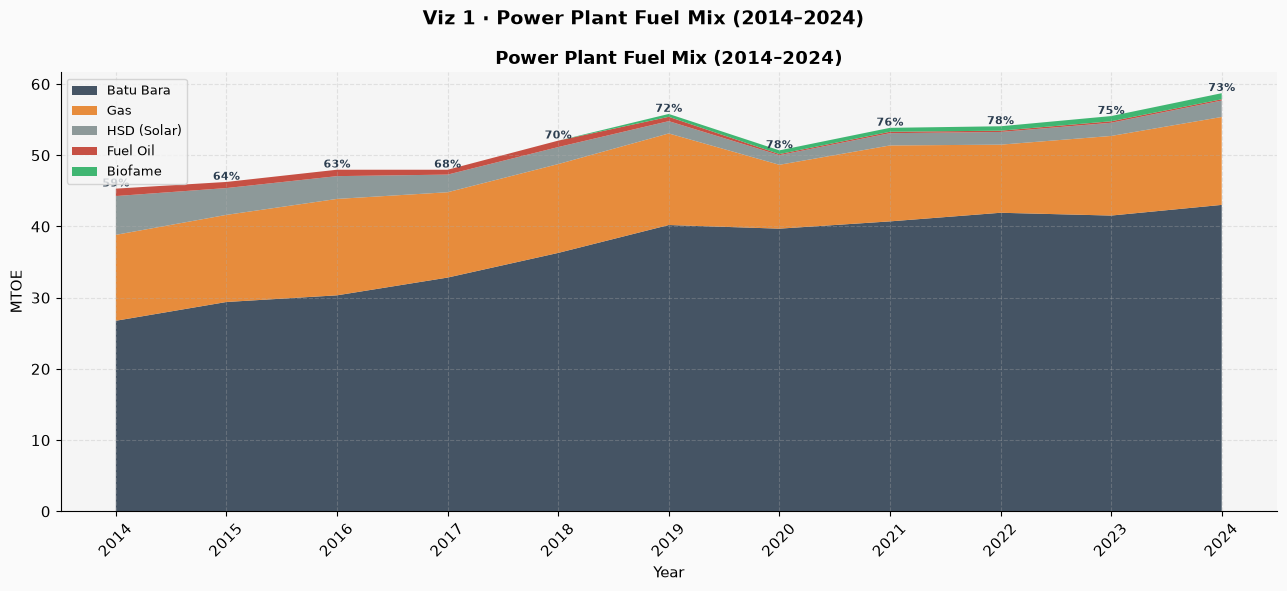

Coal share 2014: 59.1% → 2024: 73.3%


In [182]:
fig, ax = plt.subplots(figsize=(13, 6))
fig.suptitle("Viz 1 · Power Plant Fuel Mix (2014–2024)",
             fontsize=14, fontweight="bold")

fuel_cols   = ["coal_mtoe", "gas_mtoe", "hsd_mtoe", "fo_mtoe", "biofame_mtoe"]
fuel_labels = ["Batu Bara", "Gas", "HSD (Solar)", "Fuel Oil", "Biofame"]
fuel_colors = ["#2C3E50", "#E67E22", "#7F8C8D", "#C0392B", "#27AE60"]

vals = np.array([df_final[c].fillna(0).values for c in fuel_cols])
ax.stackplot(yr, vals, labels=fuel_labels, colors=fuel_colors, alpha=0.88)

total = vals.sum(axis=0)
for i, (y, t, c) in enumerate(zip(yr, total, vals[0])):
    ax.text(y, t + 0.3, f"{c/t*100:.0f}%", ha="center", fontsize=8,
            color="#2C3E50", fontweight="bold")

ax.set_xlabel("Year"); ax.set_ylabel("MTOE")
ax.set_title("Power Plant Fuel Mix (2014–2024)", fontweight="bold")
ax.legend(loc="upper left", fontsize=9)
ax.set_xticks(yr); ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.savefig("visualisasi/viz1_fuel_mix_stacked.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Coal share 2014: {df_final.coal_share.iloc[0]:.1f}% → 2024: {df_final.coal_share.iloc[-1]:.1f}%")

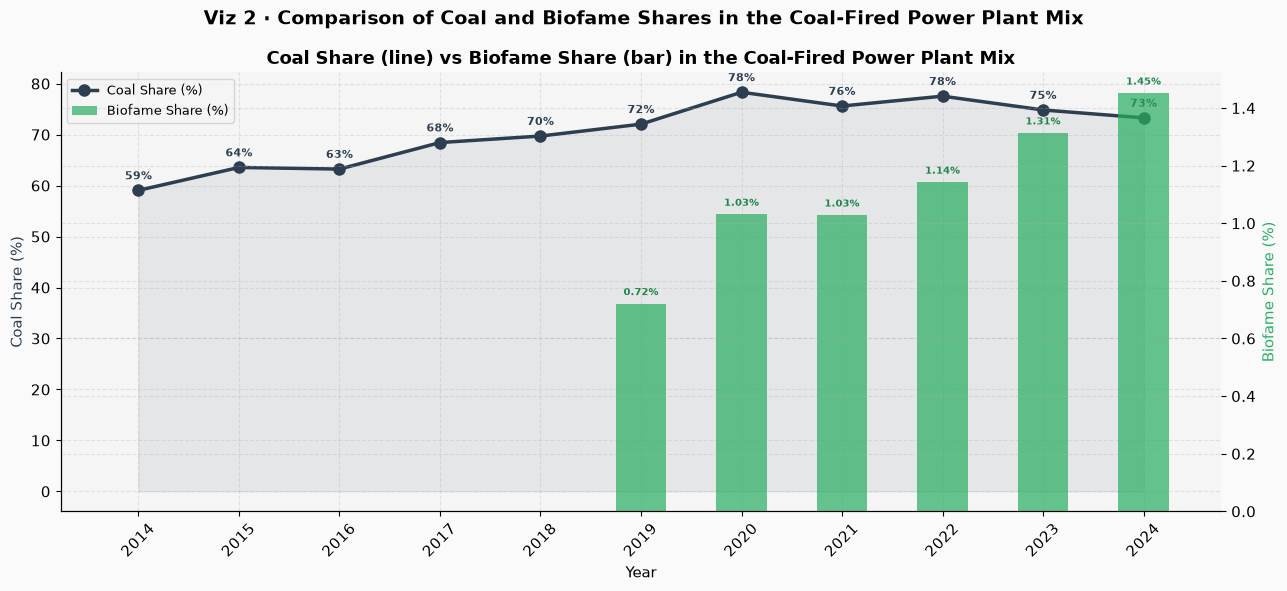

In [183]:
fig, ax1 = plt.subplots(figsize=(13, 6))
fig.suptitle("Viz 2 · Comparison of Coal and Biofame Shares in the Coal-Fired Power Plant Mix",
             fontsize=14, fontweight="bold")

ax2 = ax1.twinx()

l1, = ax1.plot(yr, df_final["coal_share"], color="#2C3E50", marker="o",
               lw=2.5, ms=8, label="Coal Share (%)")
ax1.fill_between(yr, df_final["coal_share"], alpha=0.08, color="#2C3E50")

l2 = ax2.bar(yr, df_final["re_share"], color="#27AE60", alpha=0.7,
             label="Biofame Share (%)", width=0.5)

for y, v in zip(yr, df_final["coal_share"]):
    ax1.annotate(f"{v:.0f}%", (y, v), textcoords="offset points",
                 xytext=(0, 8), ha="center", fontsize=8, color="#2C3E50", fontweight="bold")
for y, v in zip(yr, df_final["re_share"]):
    if v > 0:
        ax2.text(y, v + 0.03, f"{v:.2f}%", ha="center", fontsize=7.5,
                 color="#1E8449", fontweight="bold")

ax1.set_xlabel("Year")
ax1.set_ylabel("Coal Share (%)", color="#2C3E50")
ax2.set_ylabel("Biofame Share (%)", color="#27AE60")
ax1.set_title("Coal Share (line) vs Biofame Share (bar) in the Coal-Fired Power Plant Mix", fontweight="bold")
ax1.set_xticks(yr); ax1.tick_params(axis="x", rotation=45)
lines = [l1, l2]
ax1.legend([l1, l2], ["Coal Share (%)", "Biofame Share (%)"], fontsize=9)
plt.tight_layout()
plt.savefig("visualisasi/viz2_biofame_vs_coal.png", dpi=150, bbox_inches="tight")
plt.show()

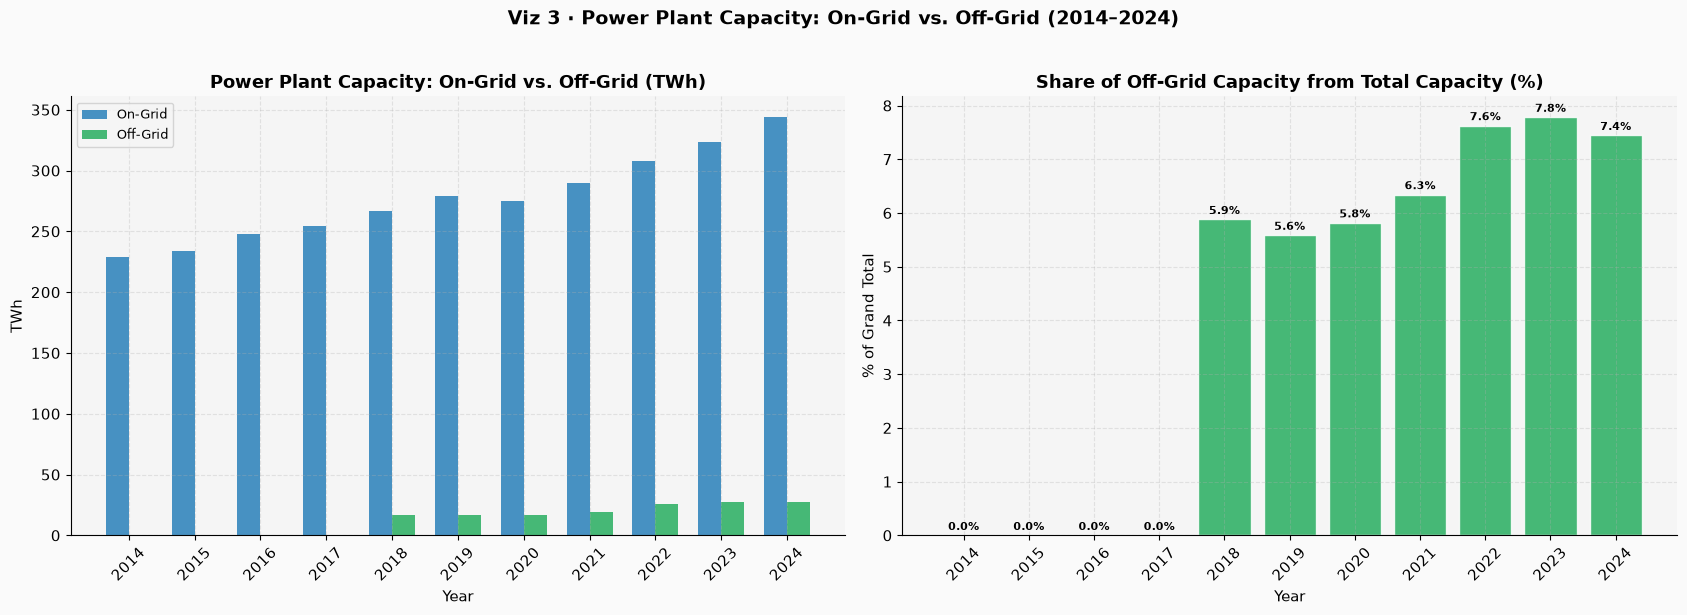

In [184]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
fig.suptitle("Viz 3 · Power Plant Capacity: On-Grid vs. Off-Grid (2014–2024)",
             fontsize=14, fontweight="bold", y=1.02)

w = 0.35; x = np.arange(len(yr))

ax = axes[0]
b1 = ax.bar(x - w/2, df_final["Total_OnGrid"]  / 1e3, w, label="On-Grid",  color="#2980B9", alpha=0.85)
b2 = ax.bar(x + w/2, df_final["Total_Off_Grid"] / 1e3, w, label="Off-Grid", color="#27AE60", alpha=0.85)
ax.set_xticks(x); ax.set_xticklabels(yr, rotation=45)
ax.set_xlabel("Year"); ax.set_ylabel("TWh")
ax.set_title("Power Plant Capacity: On-Grid vs. Off-Grid (TWh)", fontweight="bold")
ax.legend(fontsize=9)

ax2 = axes[1]
offgrid_pct = df_final["Total_Off_Grid"] / df_final["Grand_Total"] * 100
ax2.bar(yr, offgrid_pct, color="#27AE60", alpha=0.85, edgecolor="white")
for y, v in zip(yr, offgrid_pct):
    ax2.text(y, v + 0.1, f"{v:.1f}%", ha="center", fontsize=8, fontweight="bold")
ax2.set_xlabel("Year"); ax2.set_ylabel("% of Grand Total")
ax2.set_title("Share of Off-Grid Capacity from Total Capacity (%)", fontweight="bold")
ax2.set_xticks(yr); ax2.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("visualisasi/viz3_ongrid_offgrid.png", dpi=150, bbox_inches="tight")
plt.show()

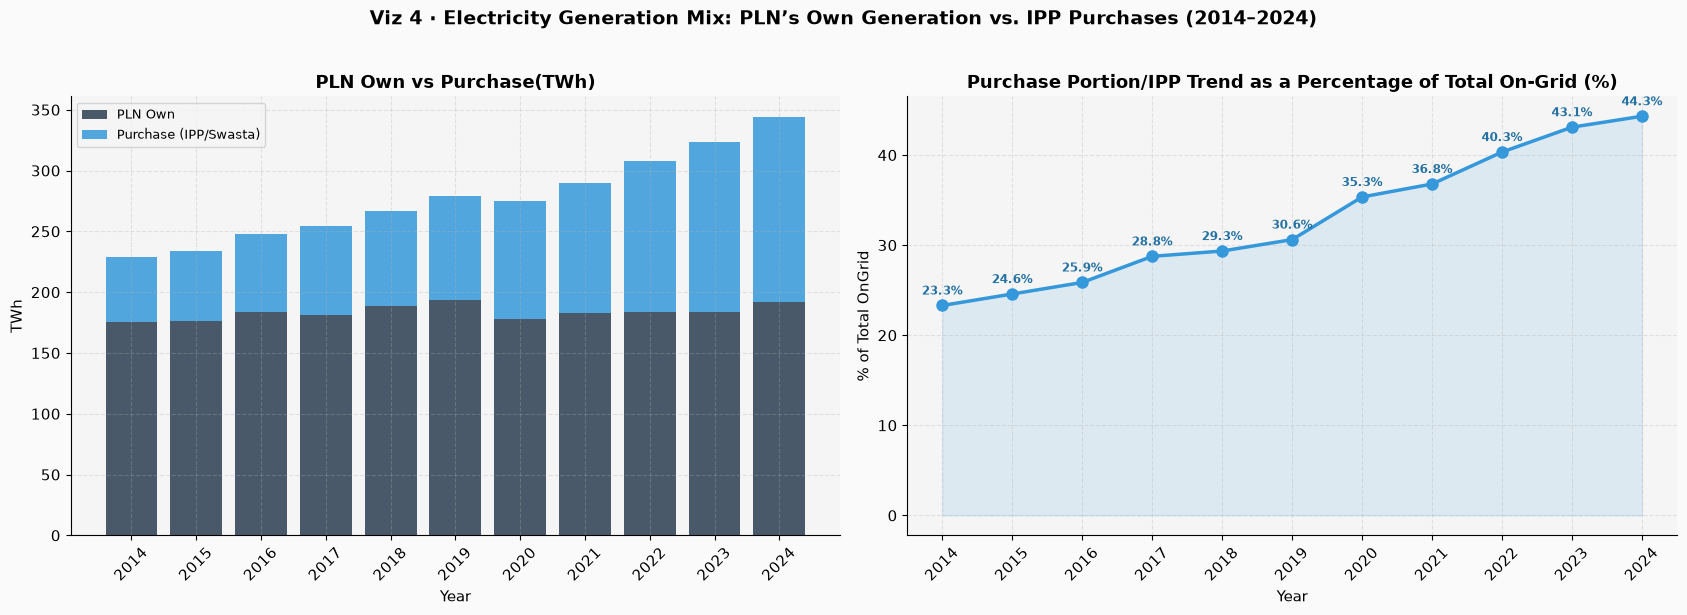

Purchase share 2014: 23.3% → 2024: 44.3%


In [185]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
fig.suptitle("Viz 4 · Electricity Generation Mix: PLN’s Own Generation vs. IPP Purchases (2014–2024)",
             fontsize=14, fontweight="bold", y=1.02)

ax = axes[0]
ax.bar(yr, df_final["Own_Sub_Total"]      / 1e3, label="PLN Own", color="#2C3E50", alpha=0.85)
ax.bar(yr, df_final["Purchase_Sub_Total"] / 1e3,
       bottom=df_final["Own_Sub_Total"] / 1e3,
       label="Purchase (IPP/Swasta)", color="#3498DB", alpha=0.85)
ax.set_xlabel("Year"); ax.set_ylabel("TWh")
ax.set_title("PLN Own vs Purchase(TWh)", fontweight="bold")
ax.legend(fontsize=9); ax.set_xticks(yr); ax.tick_params(axis="x", rotation=45)

ax2 = axes[1]
purchase_pct = df_final["Purchase_Sub_Total"] / df_final["Total_OnGrid"] * 100
ax2.plot(yr, purchase_pct, color="#3498DB", marker="o", lw=2.5, ms=8)
ax2.fill_between(yr, purchase_pct, alpha=0.12, color="#3498DB")

for y, v in zip(yr, purchase_pct):
    ax2.text(y, v + 0.9, f"{v:.1f}%", ha="center", va="bottom", fontsize=8.5,
             color="#2471A3", fontweight="bold")

ax2.set_xlabel("Year"); ax2.set_ylabel("% of Total OnGrid")
ax2.set_title("Purchase Portion/IPP Trend as a Percentage of Total On-Grid (%)", fontweight="bold")
ax2.set_xticks(yr); ax2.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.savefig("visualisasi/viz4_own_vs_purchase.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Purchase share 2014: {purchase_pct.iloc[0]:.1f}% → 2024: {purchase_pct.iloc[-1]:.1f}%")

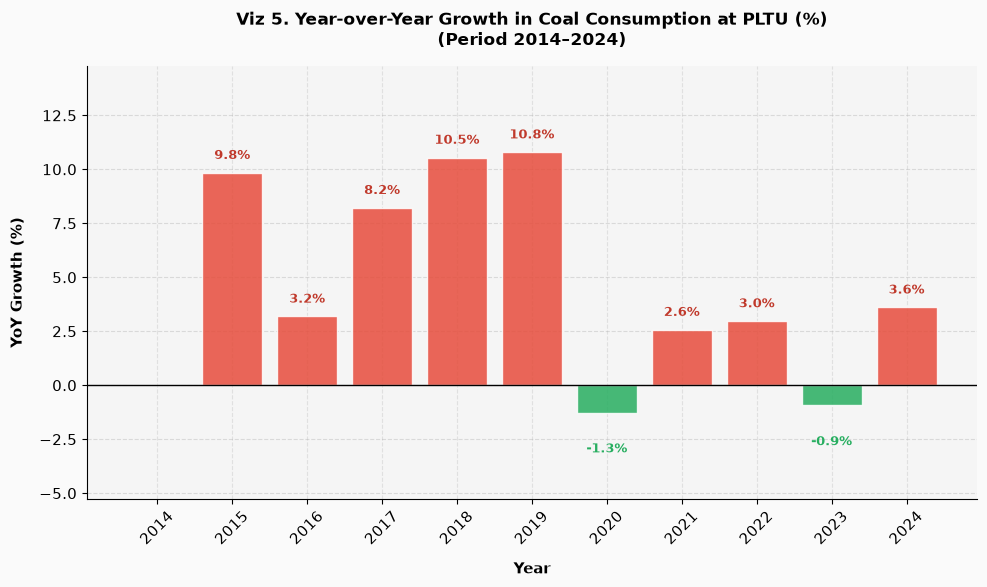

In [186]:
df_unique = df_final.drop_duplicates(subset=['Year']).sort_values('Year')
yr = df_unique['Year'].values
coal_mt = df_unique["coal_ton"] / 1e6  

yoy = coal_mt.pct_change() * 100
yoy_clean = yoy.fillna(0).values

fig, ax2 = plt.subplots(figsize=(10, 6))

bar_colors = ["#E74C3C" if v > 0 else "#27AE60" for v in yoy_clean]
ax2.bar(yr, yoy_clean, color=bar_colors, alpha=0.85, edgecolor="white", zorder=3)
ax2.axhline(0, color="black", lw=1, zorder=3)
for y, v in zip(yr, yoy_clean):
    if y == 2014:
        continue
    offset = 0.5 if v >= 0 else -1.4
    v_align = "bottom" if v >= 0 else "top"
    text_color = "#C0392B" if v >= 0 else "#27AE60"

    ax2.text(y, v + offset, f"{v:.1f}%", ha="center", va=v_align,
             fontsize=9, fontweight="bold", color=text_color)

ax2.set_xlabel("Year", fontweight="bold", labelpad=10)
ax2.set_ylabel("YoY Growth (%)", fontweight="bold", labelpad=10)
ax2.set_title("Viz 5. Year-over-Year Growth in Coal Consumption at PLTU (%)\n(Period 2014–2024)",
             fontweight="bold", fontsize=12, pad=15)

ax2.set_xticks(yr)
ax2.tick_params(axis="x", rotation=45)
ax2.set_ylim(yoy_clean.min() - 4, yoy_clean.max() + 4)
ax2.grid(True, linestyle="--", alpha=0.4, axis='y')

plt.tight_layout()
plt.savefig("visualisasi/viz5_coal_yoy_growth.png", dpi=150, bbox_inches="tight")
plt.show()


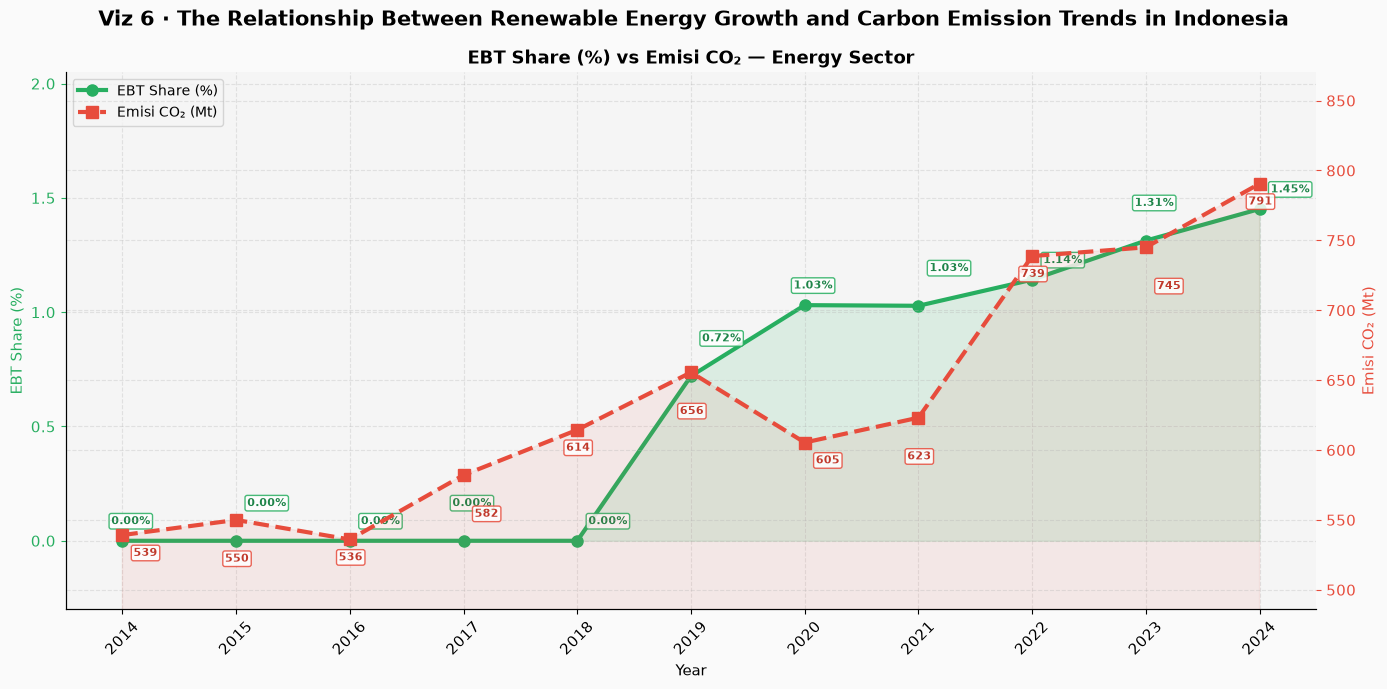

Correlation Between EBT Share and Emissions: 0.863
→ On the positive side: emissions are still rising despite the increase in renewable energy.


In [187]:
energy_mt = df_final["Energy"] / 1e3

fig, ax1 = plt.subplots(figsize=(14, 7))

fig.suptitle(
    "Viz 6 · The Relationship Between Renewable Energy Growth and Carbon Emission Trends in Indonesia",
    fontsize=15,
    fontweight="bold"
)

ax2 = ax1.twinx()

l1, = ax1.plot(
    yr,
    df_final["re_share"],
    color="#27AE60",
    marker="o",
    lw=3,
    ms=8,
    label="EBT Share (%)",
    zorder=3
)

ax1.fill_between(
    yr,
    df_final["re_share"],
    color="#27AE60",
    alpha=0.12,
    zorder=1
)

l2, = ax2.plot(
    yr,
    energy_mt,
    color="#E74C3C",
    marker="s",
    lw=3,
    ms=8,
    linestyle="--",
    label="Emisi CO₂ (Mt)",
    zorder=3
)

ax2.fill_between(
    yr,
    energy_mt,
    color="#E74C3C",
    alpha=0.08,
    zorder=1
)

for i, (x, y) in enumerate(zip(yr, df_final["re_share"])):

    offset_y = 12 if i % 2 == 0 else 25
    offset_x = -8 if i % 3 == 0 else 8

    ax1.annotate(
        f"{y:.2f}%",
        xy=(x, y),
        xytext=(offset_x, offset_y),
        textcoords="offset points",
        fontsize=8,
        color="#1E8449",
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="#27AE60",
            alpha=0.85
        )
    )

for i, (x, y) in enumerate(zip(yr, energy_mt)):

    offset_y = -15 if i % 2 == 0 else -30
    offset_x = 8 if i % 3 == 0 else -8

    ax2.annotate(
        f"{y:.0f}",
        xy=(x, y),
        xytext=(offset_x, offset_y),
        textcoords="offset points",
        fontsize=8,
        color="#C0392B",
        fontweight="bold",
        bbox=dict(
            boxstyle="round,pad=0.2",
            fc="white",
            ec="#E74C3C",
            alpha=0.85
        )
    )

ax1.set_xlabel("Year", fontsize=11)

ax1.set_ylabel(
    "EBT Share (%)",
    fontsize=11,
    color="#27AE60"
)

ax2.set_ylabel(
    "Emisi CO₂ (Mt)",
    fontsize=11,
    color="#E74C3C"
)

ax1.tick_params(axis="y", colors="#27AE60")
ax2.tick_params(axis="y", colors="#E74C3C")

ax1.set_xticks(yr)
ax1.tick_params(axis="x", rotation=45)

ax1.set_ylim(
    df_final["re_share"].min() - 0.3,
    df_final["re_share"].max() + 0.6
)

ax2.set_ylim(
    energy_mt.min() - 50,
    energy_mt.max() + 80
)

ax1.grid(
    linestyle="--",
    alpha=0.3
)

ax1.legend(
    [l1, l2],
    ["EBT Share (%)", "Emisi CO₂ (Mt)"],
    loc="upper left",
    fontsize=10
)

ax1.set_title(
    "EBT Share (%) vs Emisi CO₂ — Energy Sector",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "visualisasi/viz6_ebt_vs_emisi.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

corr = df_final["re_share"].corr(df_final["Energy"])

print(f"Correlation Between EBT Share and Emissions: {corr:.3f}")

if corr > 0:
    print("→ On the positive side: emissions are still rising despite the increase in renewable energy.")
elif corr < 0:
    print("→ Negative: an increase in EBT is associated with a decrease in emissions.")
else:
    print("→ There is no strong linear relationship.")

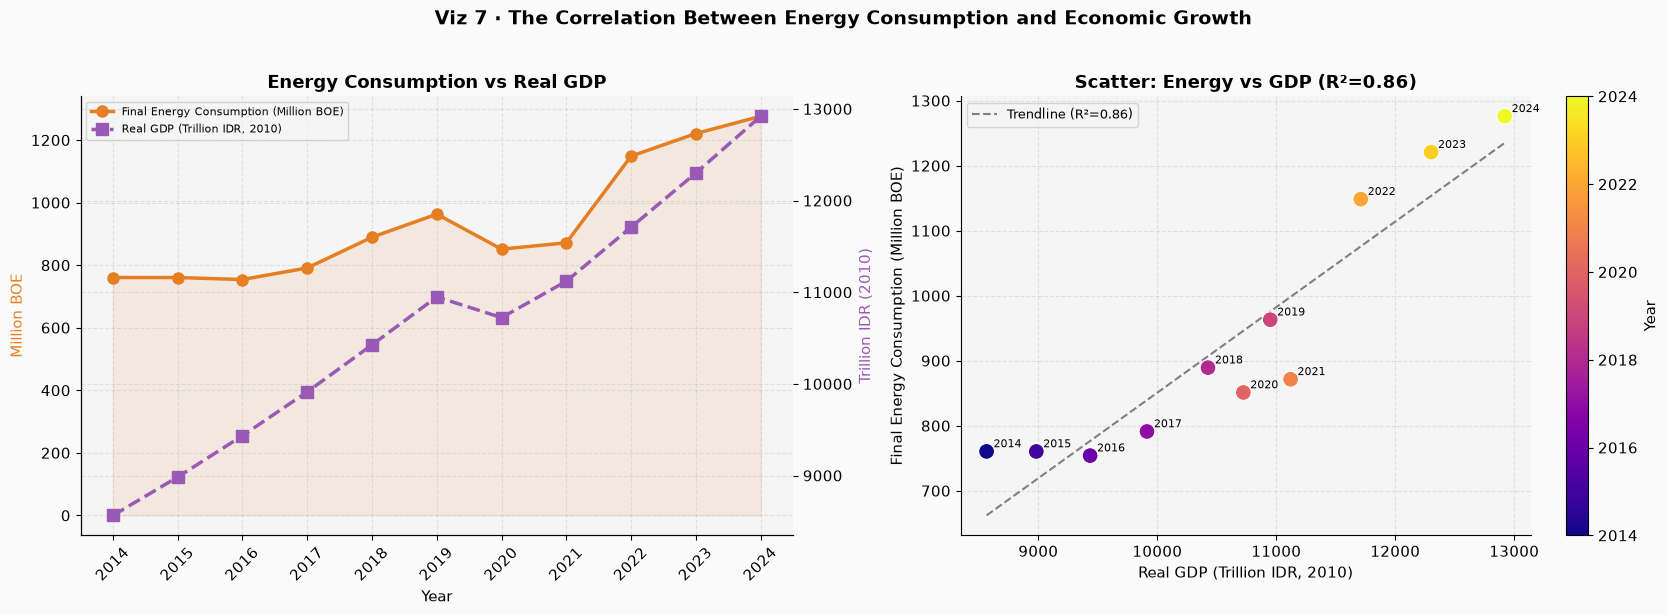

Correlation Between Energy Consumption and GDP: 0.928 (R²=0.862)
Energy Intensity 2014: 88.79 → 2024: 98.76 (Million BOE / Trillion IDR)
→ Decrease = economy becoming more energy-efficient


In [188]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
fig.suptitle("Viz 7 · The Correlation Between Energy Consumption and Economic Growth",
             fontsize=14, fontweight="bold", y=1.02)

energy = df_final["Final Energy Consumption (Thousand BOE)"] / 1e3  # juta BOE
gdp    = df_final["GDP at 2010 Constant Price (Trillion Rupiahs)"]

ax = axes[0]; axr = ax.twinx()
ax.plot(yr, energy, color="#E67E22", marker="o", lw=2.5, ms=8, label="Final Energy Consumption (Million BOE)")
ax.fill_between(yr, energy, alpha=0.1, color="#E67E22")
axr.plot(yr, gdp, color="#9B59B6", marker="s", lw=2.5, ms=8, ls="--", label="Real GDP (Trillion IDR, 2010)")
ax.set_xlabel("Year")
ax.set_ylabel("Million BOE", color="#E67E22")
axr.set_ylabel("Trillion IDR (2010)", color="#9B59B6")
ax.set_title("Energy Consumption vs Real GDP", fontweight="bold")
ax.set_xticks(yr); ax.tick_params(axis="x", rotation=45)
lines1, l1 = ax.get_legend_handles_labels()
lines2, l2 = axr.get_legend_handles_labels()
ax.legend(lines1+lines2, l1+l2, fontsize=8, loc="upper left")

ax2 = axes[1]
slope, intercept, r, p, _ = stats.linregress(gdp, energy)
gdp_line = np.linspace(gdp.min(), gdp.max(), 100)
trend    = slope * gdp_line + intercept

sc = ax2.scatter(gdp, energy, c=yr, cmap="plasma", s=130,
                 zorder=3, edgecolors="white", lw=0.8)
ax2.plot(gdp_line, trend, color="gray", ls="--", lw=1.5,
         label=f"Trendline (R²={r**2:.2f})")
plt.colorbar(sc, ax=ax2, label="Year")
for i, row in df_final.iterrows():
    ax2.annotate(str(int(row["Year"])),
                 (row["GDP at 2010 Constant Price (Trillion Rupiahs)"],
                  row["Final Energy Consumption (Thousand BOE)"] / 1e3),
                 textcoords="offset points", xytext=(5, 3), fontsize=8)
ax2.set_xlabel("Real GDP (Trillion IDR, 2010)")
ax2.set_ylabel("Final Energy Consumption (Million BOE)")
ax2.set_title(f"Scatter: Energy vs GDP (R²={r**2:.2f})", fontweight="bold")
ax2.legend(fontsize=9)

plt.tight_layout()
plt.savefig("visualisasi/viz7_energi_vs_gdp.png", dpi=150, bbox_inches="tight")
plt.show()

print(f"Correlation Between Energy Consumption and GDP: {r:.3f} (R²={r**2:.3f})")
intensity = energy / gdp * 1000
print(f"Energy Intensity 2014: {intensity.iloc[0]:.2f} → 2024: {intensity.iloc[-1]:.2f} (Million BOE / Trillion IDR)")
print("→ Decrease = economy becoming more energy-efficient")